In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [5]:
X, y_true = make_blobs(n_samples=500, centers=3, cluster_std=0.60, random_state=42)
scaler = StandardScaler()


In [6]:
df = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])
df.head()

,Feature 1,Feature 2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324


In [9]:
df

,Feature 1,Feature 2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [19]:
inertia = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

In [20]:
inertia

[1000.0000000000006,
 297.8954141051723,
 11.575484723104985,
 9.752067977356848,
 8.257175272446279,
 6.917577320416797,
 6.334755391595288,
 5.704177177901426,
 5.060234133532074,
 4.7623618981303935]

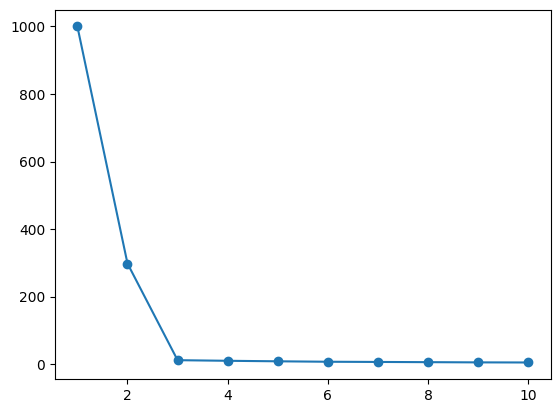

In [22]:
plt.plot(K_range, inertia, marker='o')


In [23]:
kmeans_final = KMeans(n_clusters=3, random_state=42)


In [24]:
cluster_labels = kmeans_final.fit_predict(X_scaled)

In [31]:
df['cluster'] = cluster_labels

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

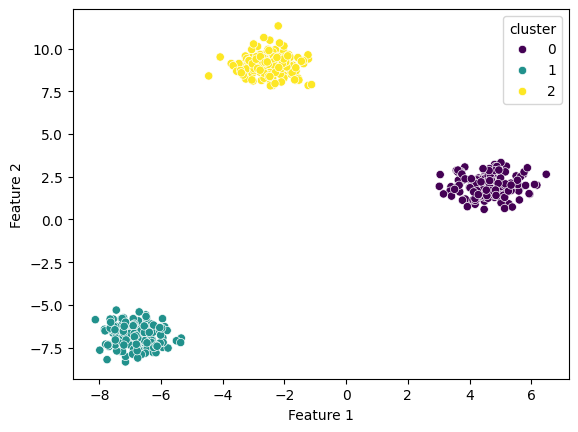

In [32]:
sns.scatterplot(x =df['Feature 1'],y=df['Feature 2'],hue=df['cluster'], palette = 'viridis')

In [33]:
from sklearn.datasets import make_moons
X, y_true = make_moons(n_samples=200, noise=0.05, random_state=42)

In [34]:
from sklearn.cluster import KMeans, DBSCAN

In [35]:
df = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])
df.head()

,Feature 1,Feature 2
0,-1.020690,0.105518
1,0.905826,0.457858
2,0.618422,0.757086
3,1.227707,-0.425185
4,0.329356,-0.206946


In [36]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [37]:
kmeans_final = KMeans(n_clusters=2, random_state=42)
cluster_labels = kmeans_final.fit_predict(X_scaled)

In [38]:
df['kmeans_cluster'] = cluster_labels

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

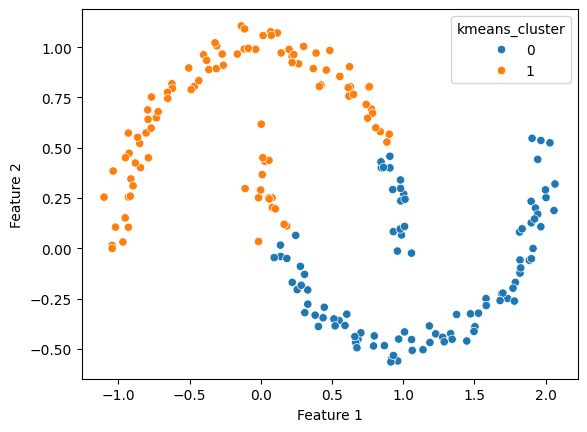

In [39]:
sns.scatterplot(x =df['Feature 1'],y=df['Feature 2'],hue=df['kmeans_cluster'], palette = 'tab10')
#

In [46]:
dbscan_final = DBSCAN(eps=0.4, min_samples=5)
cluster_labels = dbscan_final.fit_predict(X_scaled)

In [47]:
df['dbscan_cluster'] = cluster_labels

<Axes: xlabel='Feature 1', ylabel='Feature 2'>

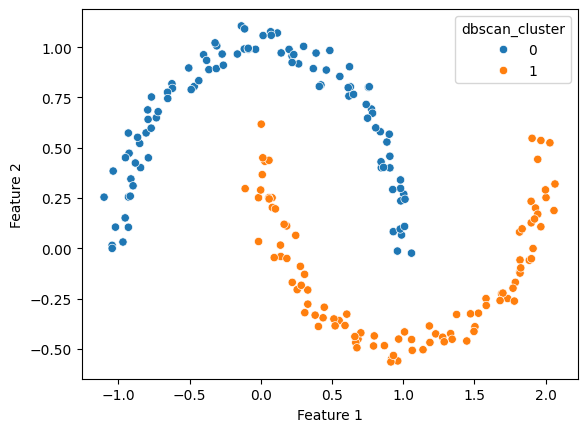

In [48]:
sns.scatterplot(x =df['Feature 1'],y=df['Feature 2'],hue=df['dbscan_cluster'], palette = 'tab10')
#